# PART A: Assess and Validate Your Prepared Data — Quality, Inspection, and Rules

### Activity A0: Quality Gate Plan

#### Objective

To establish quality checks for the prepared CloudJoi corpus before it is used in the TicketWise AI support assistant. The quality gate focuses on ensuring that the data is complete, consistent, accurate, traceable and suitable for answering ticket-related enquiries.

### Quality Gate Plan

| Topic 2 Requirement | Required Data/Evidence | Quality Concern | Observable Check | Possible Decision |
|---|---|---|---|---|
| **FR1:** Answer ticket-related enquiries using official CloudJoi information. | Relevant FAQ, Ticketing Terms and Refund Policy content. | Missing information, inconsistent content, inaccurate extraction or outdated policies. | Check whether all three sources are available, records contain meaningful text, and the content can be traced to its original source. | Accept if the required information is available and traceable. Review or hold records with missing, unclear or potentially outdated information. |
| **FR2:** Identify relevant CloudJoi documents and provide supporting source references. | Unique record IDs, source filenames and source metadata. | Missing metadata, duplicate IDs or incorrect source references. | Check for missing record IDs, duplicate IDs, missing source filenames and missing source fingerprints. | Accept records with complete and traceable metadata. Review or quarantine records with missing or inconsistent metadata. |

### Explanation

The quality gate plan ensures that the prepared corpus contains reliable and traceable information for TicketWise.

FR1 requires meaningful and relevant CloudJoi content so that the assistant can answer ticket-related enquiries. FR2 requires complete source information so that the assistant can identify where its answers come from.

Therefore, the corpus must be checked for missing content, inconsistent information, duplicate records and incomplete source metadata before it is used in later stages.

### Activity A1: Load and Verify the Topic 3 Prepared-Data Hand-off

#### Objective

To load the prepared corpus from Topic 3 and verify that the records can be accessed correctly before performing data quality assessment.

The Topic 3 pipeline produced `prepared_text.jsonl`, containing structured records from three official CloudJoi documents. Since the original pipeline did not produce the lecturer's expected `prepared_chunks.jsonl` and `chunks.pkl` files, the actual Topic 3 output will be used as the main input. A compatible chunk structure will be generated from the JSONL records for the subsequent lab activities.

In [1]:
# Install the required libraries
!pip install -q pandera pandas matplotlib

# Upload the Topic 3 prepared JSONL file
from google.colab import files

uploaded = files.upload()

Saving prepared_text.jsonl to prepared_text (2).jsonl


#### A1 – Load and inspect the prepared data

In [2]:
import json

# Load the prepared JSONL file
records = []

with open("prepared_text.jsonl", "r", encoding="utf-8") as file:
    for line in file:
        records.append(json.loads(line))

# Display the total number of records
print("Total records:", len(records))

# Display the fields in the first record
print("\nFirst record:")
print(records[0])

# Check whether all records have the expected fields
required_fields = [
    "record_id",
    "text",
    "source",
    "source_sha256",
    "processing",
    "page"
]

print("\nAll records contain the required fields:",
      all(all(field in record for field in required_fields)
          for record in records))

Total records: 41

First record:
{'record_id': 'faq-introduction-001', 'text': 'Introduction\nDiscover everything you need to know about buying tickets, streaming live and on-demand shows, and enjoying unforgettable experiences with CloudJoi – your ultimate ticketing, streaming, and community platform in Malaysia!', 'source': 'cloudjoi_faq.pdf', 'source_sha256': '177c3487fdb336346ba5d4657ac16e0403927784d829b97f3a68a4d9f7139efc', 'processing': 'faq-question-answer-extraction', 'page': None}

All records contain the required fields: True


In [3]:
# Convert JSONL records into compatible chunks.pkl format

import pickle
from types import SimpleNamespace

# Convert JSONL records into the expected chunk structure
chunks = []

for record in records:
    chunk = SimpleNamespace(
        page_content=record["text"],
        metadata={
            "record_id": record["record_id"],
            "source": record["source"],
            "source_sha256": record["source_sha256"],
            "processing": record["processing"],
            "page": record["page"]
        }
    )

    chunks.append(chunk)

# Save the chunks as a pickle file
with open("chunks.pkl", "wb") as file:
    pickle.dump(chunks, file)

print("Total chunks created:", len(chunks))
print("Pickle file created: chunks.pkl")

Total chunks created: 41
Pickle file created: chunks.pkl


In [4]:
# Verify the JSONL and PKL record counts
# Reload the pickle file
with open("chunks.pkl", "rb") as file:
    loaded_chunks = pickle.load(file)

# Compare the record counts
print("JSONL records:", len(records))
print("PKL chunks:", len(loaded_chunks))

# Check whether both counts match
print("\nRecord counts match:", len(records) == len(loaded_chunks))

# Display one converted chunk
print("\nFirst chunk text:")
print(loaded_chunks[0].page_content)

print("\nFirst chunk metadata:")
print(loaded_chunks[0].metadata)

JSONL records: 41
PKL chunks: 41

Record counts match: True

First chunk text:
Introduction
Discover everything you need to know about buying tickets, streaming live and on-demand shows, and enjoying unforgettable experiences with CloudJoi – your ultimate ticketing, streaming, and community platform in Malaysia!

First chunk metadata:
{'record_id': 'faq-introduction-001', 'source': 'cloudjoi_faq.pdf', 'source_sha256': '177c3487fdb336346ba5d4657ac16e0403927784d829b97f3a68a4d9f7139efc', 'processing': 'faq-question-answer-extraction', 'page': None}


### Activity A2: Data Quality Inventory

#### Objective

To identify potential data quality issues in the prepared CloudJoi corpus, including missing information, corrupted text, inconsistent metadata, noisy content and duplicate records.

In [5]:
# Inspect the structure and quality of the prepared data

import pandas as pd

# Convert the records into a DataFrame for inspection
df = pd.DataFrame(records)

# Display the dataset overview
print("Dataset shape:", df.shape)

print("\nMissing values in each field:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

print("\nNumber of unique record IDs:", df["record_id"].nunique())

print("\nNumber of records by source:")
print(df["source"].value_counts())

Dataset shape: (41, 6)

Missing values in each field:
record_id         0
text              0
source            0
source_sha256     0
processing        0
page             41
dtype: int64

Data types:
record_id        object
text             object
source           object
source_sha256    object
processing       object
page             object
dtype: object

Number of unique record IDs: 41

Number of records by source:
source
cloudjoi_faq.pdf                23
cloudjoi_ticketing_terms.pdf    17
cloudjoi_refund_policy.pdf       1
Name: count, dtype: int64


In [6]:
# Check for missing, corrupted and noisy data
import re

# Check for empty or whitespace-only text
empty_text = [
    r["record_id"] for r in records
    if not r["text"].strip()
]

# Check for corrupted characters
corrupted_text = [
    r["record_id"] for r in records
    if "\x00" in r["text"] or "\ufffd" in r["text"]
]

# Check for excessive whitespace
noisy_text = [
    r["record_id"] for r in records
    if re.search(r"\n{4,}| {4,}", r["text"])
]

# Display the results
print("Empty text records:", len(empty_text), empty_text)
print("Corrupted text records:", len(corrupted_text), corrupted_text)
print("Records with excessive whitespace:", len(noisy_text), noisy_text)

Empty text records: 0 []
Corrupted text records: 0 []
Records with excessive whitespace: 0 []


### A3 – Inspect sample records manually

In [7]:
# Display selected records for manual inspection
sample_ids = [
    "faq-018",
    "ticketing-terms-006",
    "ticketing-terms-016"
]

for record in records:
    if record["record_id"] in sample_ids:
        print("=" * 70)
        print("Record ID:", record["record_id"])
        print("Source:", record["source"])
        print("Text:")
        print(record["text"])
        print()

Record ID: faq-018
Source: cloudjoi_faq.pdf
Text:
Category: Watching Online
Question: My chat box kept loading without any content.
Answer: Kindly clear cache and reload your browser. If the problem persists, please contact us via for help.

Record ID: ticketing-terms-006
Source: cloudjoi_ticketing_terms.pdf
Text:
Admission
Only valid ticket holders will be granted admission to the event.
Proof of identity may be required to shown to obtain discounts and upon
admission such as student identification, MyKad or Passport for senior
citizens.
Venue Owner or Event Organiser reserves the right without refund or
compensation to refuse admission to any persons whose conduct is
disorderly or unbecoming.
Infants in arms or children without tickets will not be admitted for safety
reasons.
Latecomers can only be admitted at a suitable break during the performance
at the discretion of the Venue Owner. However, admission cannot be
guaranteed and no refund request would be entertained.
The Ticket Hol

#### A3 – Manual Inspection Observations

Three records were selected for manual inspection:

1. **FAQ-018:** The phrase "please contact us via for help" appears incomplete because the contact method is not specified.

2. **Ticketing Terms-006:** The phrase "Proof of identity may be required to shown" contains a possible grammatical error.

3. **Ticketing Terms-016:** The heading contains the spelling "Compliants" instead of "Complaints".

These observations suggest possible source-content or text-extraction issues that cannot be detected through basic automated validation. The original PDF documents should be checked to determine whether the issues originated from the source documents or the extraction process.

**Reflection:** Automated checks can identify missing fields, duplicate IDs and corrupted characters, but they cannot fully determine whether extracted sentences are grammatically correct or meaningful. Therefore, manual inspection is also necessary to assess data quality.

### A4 – Define data validation rules using Pandera

In [8]:
import pandera.pandas as pa
from pandera.pandas import Column, DataFrameSchema, Check

# Define the allowed processing methods found in the dataset
allowed_processing = [
    "faq-question-answer-extraction",
    "section-aware",
    "document-level"
]

# Define the data validation schema
schema = DataFrameSchema({
    "record_id": Column(
        str,
        Check.str_length(min_value=1),
        unique=True,
        nullable=False
    ),
    "text": Column(
        str,
        Check.str_length(min_value=1),
        nullable=False
    ),
    "source": Column(
        str,
        Check.str_length(min_value=1),
        nullable=False
    ),
    "source_sha256": Column(
        str,
        Check.str_length(min_value=1),
        nullable=False
    ),
    "processing": Column(
        str,
        Check.isin(allowed_processing),
        nullable=False
    ),
    "page": Column(
        object,
        nullable=True
    )
})

print("Validation schema created successfully.")

Validation schema created successfully.


In [9]:
# Apply the validation schema to the dataset
try:
    validated_df = schema.validate(df, lazy=True)

    print("Validation completed successfully!")
    print("Total records checked:", len(validated_df))
    print("All records passed validation.")

except pa.errors.SchemaErrors as err:
    print("Validation completed with errors.")

    # Display the validation failures
    failures = err.failure_cases

    print("\nTotal validation failures:", len(failures))
    display(failures)

Validation completed successfully!
Total records checked: 41
All records passed validation.


#### A4 – Validation Results
The Pandera validation schema was applied to all 41 records using five validation rules. All 41 records passed the validation checks. No validation failures were detected.


The results confirm that the dataset contains unique record IDs, non-empty text, complete source metadata and consistent processing methods. Missing page numbers were allowed because the Topic 3 pipeline did not capture page-level information.

However, passing these automated checks does not guarantee content accuracy. The possible wording and spelling issues identified during manual inspection in A3 still require further review.

In [10]:
# Create an empty validation failure report
failure_columns = ["schema_context", "column", "check", "failure_case"]

validation_failures = pd.DataFrame(columns=failure_columns)

# Save the report
validation_failures.to_csv(
    "/content/week4_validation_failures.csv",
    index=False
)

print("Validation failure report saved.")
print("Total validation failures:", len(validation_failures))

Validation failure report saved.
Total validation failures: 0


### A5 – Classify and Triage Flagged Cases

The following table summarises the three potential data quality issues identified during manual inspection in A3.

| Record ID | Observation | Classification | Action | Reason |
|---|---|---|---|---|
| faq-018 | Incomplete contact phrase: "please contact us via for help." | Uncertain | Review | The contact method is missing. The original PDF must be checked to determine whether this came from the source or extraction process. |
| ticketing-terms-006 | Possible grammatical error: "required to shown." | Uncertain | Review | The wording may be a source typo or extraction issue. It should not be corrected without checking the original PDF. |
| ticketing-terms-016 | Heading contains "Compliants" instead of "Complaints". | Uncertain | Review | The spelling may already exist in the original document or may have been introduced during extraction. |


**Triage Decision:**

All three cases are classified as uncertain because the original PDF documents have not yet been compared with the extracted text. The records will be retained temporarily while awaiting manual review. No automatic corrections or removals will be made to avoid changing the original CloudJoi information without evidence.

If the original PDFs confirm that the issues are present in the source documents, they will be documented as source-content issues. If the PDFs contain correct wording, the affected records will be reviewed for extraction errors and corrected only when supported by the original source.



In [11]:
# Check for duplicate records

# Check for exact duplicate text
duplicate_review = df[
    df["text"].duplicated(keep=False)
].copy()

# Save the duplicate review results
duplicate_review.to_csv(
    "/content/week4_duplicate_review.csv",
    index=False
)

print("Duplicate review completed.")
print("Duplicate records found:", len(duplicate_review))

if len(duplicate_review) == 0:
    print("No exact duplicate text records were detected.")
else:
    display(duplicate_review[
        ["record_id", "source", "text"]
    ])

Duplicate review completed.
Duplicate records found: 0
No exact duplicate text records were detected.


# PART B: Review Duplicates, Coverage, Bias Propagation, and Responsible Data Risks

### Activity B1: Deduplication and Data Cleaning

### Objective

To remove exact duplicate records from the prepared CloudJoi corpus while preserving the original text and source metadata.

The cleaning process will use normalized text to identify duplicate records. The original text and metadata will be retained for all records that pass the deduplication process.

In [12]:
# Normalize text and identify exact duplicates using SHA-256

import hashlib
import re

def normalize_text(text):
    text = re.sub(r"\s+", " ", text)
    return text.strip()

cleaned_records = []
seen_hashes = set()
removed_duplicates = []

for record in records:
    normalized = normalize_text(record["text"])

    # Generate a SHA-256 hash
    text_hash = hashlib.sha256(
        normalized.encode("utf-8")
    ).hexdigest()

    if text_hash in seen_hashes:
        removed_duplicates.append(record["record_id"])
    else:
        seen_hashes.add(text_hash)
        cleaned_records.append(record)

print("Original records:", len(records))
print("Cleaned records:", len(cleaned_records))
print("Duplicates removed:", len(removed_duplicates))
print("Removed record IDs:", removed_duplicates)

Original records: 41
Cleaned records: 41
Duplicates removed: 0
Removed record IDs: []


In [13]:
# Save the cleaned records as a JSONL file
with open("/content/prepared_chunks_clean.jsonl", "w", encoding="utf-8") as file:
    for record in cleaned_records:
        file.write(json.dumps(record, ensure_ascii=False) + "\n")

print("Cleaned JSONL file saved successfully.")
print("Total records saved:", len(cleaned_records))

Cleaned JSONL file saved successfully.
Total records saved: 41


In [14]:
# Convert cleaned records into compatible chunks
cleaned_chunks = []

for record in cleaned_records:
    chunk = SimpleNamespace(
        page_content=record["text"],
        metadata={
            "record_id": record["record_id"],
            "source": record["source"],
            "source_sha256": record["source_sha256"],
            "processing": record["processing"],
            "page": record["page"]
        }
    )

    cleaned_chunks.append(chunk)

# Save the cleaned chunks as a pickle file
with open("/content/chunks_clean.pkl", "wb") as file:
    pickle.dump(cleaned_chunks, file)

print("Cleaned PKL file saved successfully.")
print("Total chunks saved:", len(cleaned_chunks))

Cleaned PKL file saved successfully.
Total chunks saved: 41


In [15]:
# Verify the cleaned JSONL and PKL files

# Reload the cleaned JSONL file
with open("/content/prepared_chunks_clean.jsonl", "r", encoding="utf-8") as file:
    verified_jsonl = [json.loads(line) for line in file]

# Reload the cleaned PKL file
with open("/content/chunks_clean.pkl", "rb") as file:
    verified_pkl = pickle.load(file)

# Compare the record counts
print("Cleaned JSONL records:", len(verified_jsonl))
print("Cleaned PKL chunks:", len(verified_pkl))

# Verify that both files contain matching records
print("\nRecord counts match:",
      len(verified_jsonl) == len(verified_pkl))

# Verify that the text and metadata are preserved
print("Text and metadata preserved:",
      all(
          record["text"] == chunk.page_content
          and record["record_id"] == chunk.metadata["record_id"]
          and record["source"] == chunk.metadata["source"]
          for record, chunk in zip(verified_jsonl, verified_pkl)
      ))

Cleaned JSONL records: 41
Cleaned PKL chunks: 41

Record counts match: True
Text and metadata preserved: True


In [16]:
# Save duplicate review results

import os

os.makedirs("/content/docs", exist_ok=True)

pd.DataFrame(
    columns=["hash", "duplicate_source", "first_source", "preview"]
).to_csv(
    "/content/docs/week4_duplicate_review.csv",
    index=False
)

print("Duplicate review CSV saved.")
print("Exact duplicates found:", len(removed_duplicates))

Duplicate review CSV saved.
Exact duplicates found: 0


### Activity B2: Data Coverage Analysis

#### Objective

To examine the distribution of prepared records across the three CloudJoi source documents and assess whether the corpus provides sufficient coverage of the information required by the TicketWise project.

The analysis will identify how much each source contributes to the prepared corpus and whether the available content represents the project's ticketing-related requirements.

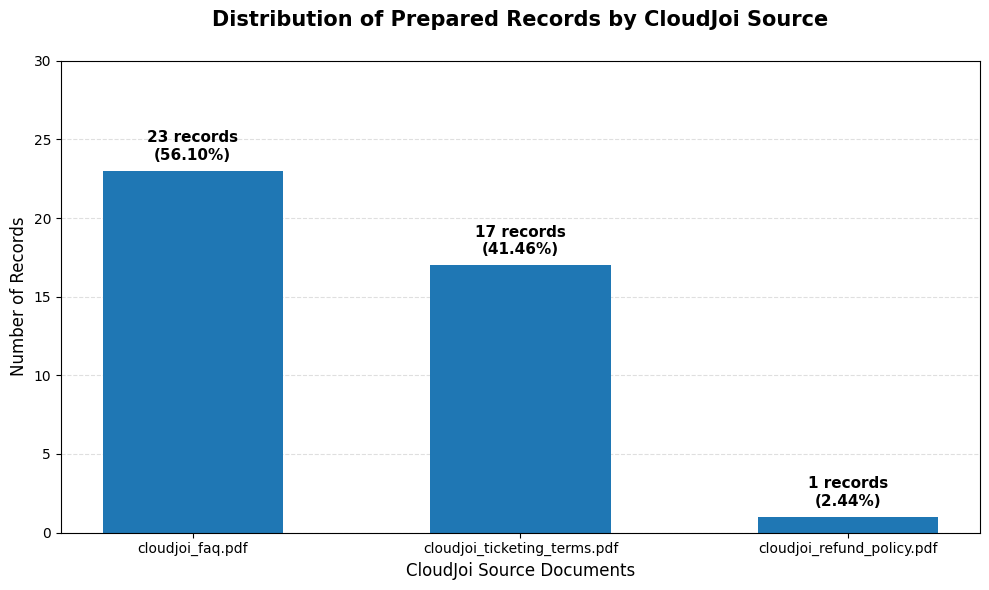

In [17]:
import matplotlib.pyplot as plt

# Count records by source
source_counts = pd.Series(
    [record["source"] for record in cleaned_records]
).value_counts()

# Calculate percentages
source_percentages = (source_counts / len(cleaned_records)) * 100

# Create a larger chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    source_counts.index,
    source_counts.values,
    width=0.55
)

# Add count and percentage labels above each bar
for bar, percentage in zip(bars, source_percentages):
    height = bar.get_height()

    ax.annotate(
        f'{int(height)} records\n({percentage:.2f}%)',
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

# Improve chart appearance
ax.set_title(
    "Distribution of Prepared Records by CloudJoi Source",
    fontsize=15,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("CloudJoi Source Documents", fontsize=12)
ax.set_ylabel("Number of Records", fontsize=12)

ax.set_ylim(0, 30)
ax.tick_params(axis="x", labelrotation=0, labelsize=10)
ax.tick_params(axis="y", labelsize=10)

ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()

# Save the improved chart
plt.savefig(
    "/content/week4_coverage_by_source.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### B2 – Assess Content Coverage Against Project Requirements

The prepared corpus was assessed against two functional requirements from Topic 2.

- **FR1:** The corpus should contain relevant information about ticket purchasing, ticket retrieval, streaming and refunds to support ticket-related enquiries.
- **FR2:** Each record should retain sufficient source information to identify the original CloudJoi document and support source traceability.

The assessment focuses on whether the available documents provide relevant information for these requirements, rather than relying only on the number of records.

In [18]:
# Inspect content coverage by source

# Display the records grouped by source
for source in sorted(df["source"].unique()):
    print("\n" + "=" * 70)
    print("SOURCE:", source)
    print("=" * 70)

    source_records = df[df["source"] == source]

    for _, record in source_records.iterrows():
        print("\nRecord ID:", record["record_id"])
        print("Text:", record["text"][:300])


SOURCE: cloudjoi_faq.pdf

Record ID: faq-introduction-001
Text: Introduction
Discover everything you need to know about buying tickets, streaming live and on-demand shows, and enjoying unforgettable experiences with CloudJoi – your ultimate ticketing, streaming, and community platform in Malaysia!

Record ID: faq-001
Text: Category: Ticketing Process
Question: Is there a time limit when purchasing tickets online?
Answer: All seats are reserved for 15 minutes. If the booking is not finalized within this time frame, the seats will be released for the next potential buyer.

Record ID: faq-002
Text: Category: Ticketing Process
Question: Why am I encountering a credit card error at checkout?
Answer: If you've reached the purchase page, entered your card number, and submitted your order, but received a credit card error message, we suggest double-checking your card details and available funds, th

Record ID: faq-003
Text: Category: Ticketing Process
Question: Why is there a ticket limit whe

In [19]:
# Define the main enquiry topics for TicketWise
topic_keywords = {
    "Ticket Purchasing": [
        "purchase", "purchasing", "booking", "buy tickets"
    ],
    "Ticket Retrieval": [
        "retrieve", "download", "my tickets", "confirmation email"
    ],
    "Refunds and Exchanges": [
        "refund", "exchange", "cancellation", "postponed"
    ],
    "Streaming and On-Demand": [
        "streaming", "stream", "on-demand", "passcode"
    ],
    "Admission": [
        "admission", "ticket holders", "venue"
    ]
}

# Count records containing keywords for each topic
coverage_results = []

for topic, keywords in topic_keywords.items():
    matching_records = [
        record for record in cleaned_records
        if any(keyword in record["text"].lower() for keyword in keywords)
    ]

    coverage_results.append({
        "Topic": topic,
        "Records Found": len(matching_records),
        "Record IDs": ", ".join(
            record["record_id"] for record in matching_records
        )
    })

coverage_df = pd.DataFrame(coverage_results)

print("Topic Coverage Results:")
display(coverage_df)

Topic Coverage Results:


,Topic,Records Found,Record IDs
0,Ticket Purchasing,25,"faq-001, faq-002, faq-003, faq-004, faq-006, f..."
1,Ticket Retrieval,4,"faq-006, faq-007, faq-008, faq-009"
2,Refunds and Exchanges,12,"faq-011, faq-012, faq-013, ticketing-terms-003..."
3,Streaming and On-Demand,6,"faq-introduction-001, faq-017, faq-019, faq-02..."
4,Admission,6,"faq-010, ticketing-terms-006, ticketing-terms-..."


#### B2 – Content Coverage Findings

The keyword-based coverage analysis identified records related to five ticketing enquiry topics:

| Topic | Records Found |
|---|---:|
| Ticket Purchasing | 25 |
| Ticket Retrieval | 4 |
| Refunds and Exchanges | 12 |
| Streaming and On-Demand | 6 |
| Admission | 6 |

The results show that the prepared corpus contains information relevant to all five topics. Ticket purchasing has the highest number of matching records (25), followed by refunds and exchanges (12). Ticket retrieval has the lowest number of matching records (4).

The FAQ provides information about purchasing, ticket retrieval, refunds, streaming and on-demand viewing. The Ticketing Terms provide additional information about admission requirements, refunds and ticket conditions. The Refund Policy provides a separate source for refund-related information.

However, keyword matching does not guarantee that every enquiry can be answered completely. Some relevant information may not contain the selected keywords, while some matching records may only mention a topic briefly.

**Coverage Decision:**

The corpus provides an initial level of content coverage for the main ticketing enquiry topics required by TicketWise. However, further manual review is needed to confirm whether the information is sufficiently detailed and consistent for answering user enquiries.

The Refund Policy is also represented by only one document-level record. Although this record contains refund information, its content should be checked carefully to ensure that important policy details are not overlooked.

#### B2 – Coverage Adequacy Criteria

For this project, adequate coverage means:

1. All three official CloudJoi documents are represented in the prepared corpus.
2. The main ticketing enquiry topics required by TicketWise have relevant supporting records.
3. Each record retains its original source information to support traceability.
4. Important policy information, especially refund conditions, is available and can be checked against the original document.

Based on these criteria, the corpus meets the initial source and topic coverage requirements. However, content completeness and accuracy still require manual verification before the corpus can be approved for future use.


#### B2 – Coverage Reflection

The Refund Policy appears to have the lowest record count, with only one document-level record (2.44% of the prepared corpus).

However, this does not automatically indicate a genuine coverage gap because the Refund Policy was processed as one document-level record, while the FAQ and Ticketing Terms were divided into smaller records.

The available evidence confirms that refund-related information is present in the corpus. However, the adequacy and completeness of that information cannot be determined from record counts alone.

Therefore, the lower record count is currently considered a difference in document processing and record quantity. Further content-level inspection is required to determine whether all important refund conditions are sufficiently represented.

### Activity B3: Representation and Bias Analysis

#### Objective

To identify potential representation and bias risks in the prepared CloudJoi corpus and examine how these risks could affect the information retrieved and presented by TicketWise.

The analysis focuses on the distribution of source documents, content coverage and possible information gaps. Since retrieval and generation have not yet been implemented, the analysis identifies potential risks rather than claiming that actual AI bias has occurred.

#### B3 – Bias Risk 1: Uneven Source Representation

**Evidence:**

The prepared corpus contains 41 records:
- FAQ: 23 records (56.10%)
- Ticketing Terms: 17 records (41.46%)
- Refund Policy: 1 record (2.44%)

The three documents also use different processing methods. The FAQ contains multiple question-and-answer records, while the Refund Policy is stored as one document-level record.

**Potential impact:**

The difference in record distribution and processing methods may affect how easily information from each source can be retrieved. For example, individual FAQ questions may be easier to match with a user's enquiry because they are stored as separate records. In contrast, the Refund Policy is stored as one large record, which may make specific refund conditions harder to identify.

**Possible propagation:**

Source documents and processing methods → Uneven record representation → Different opportunities for information retrieval → Users may receive more FAQ-based answers while specific refund information may be overlooked.

**Mitigation:**

- Review whether document-level records should be divided into smaller meaningful sections.
- Ensure that important refund conditions remain available as separate, identifiable information.
- Test future retrieval using questions from all three source documents.
- Compare whether relevant information from each source can be retrieved successfully.

#### B3 – Bias Risk 2: Limited and Potentially Outdated Information

**Evidence:**

The prepared corpus contains information from only three official CloudJoi documents. The Refund Policy record states that it was last updated on 4 May 2025. The publication dates of the FAQ and Ticketing Terms have not been verified.

**Potential impact:**

The available documents may not represent every current CloudJoi policy, procedure or customer enquiry. If the information changes but the prepared corpus is not updated, TicketWise may provide outdated or incomplete answers.

**Possible propagation:**

Limited or outdated source documents → Missing or outdated information in the prepared corpus → Relevant current information may not be retrieved → Users may receive incorrect or incomplete guidance.

**Mitigation:**

- Check the official CloudJoi website regularly for updated documents.
- Record the source document's last-updated date or retrieval date when available.
- Reprocess the corpus when official documents change.
- Test whether answers involving important policies match the latest available official information.

#### B3 – Overall Bias Assessment

The analysis identified two potential risks: uneven source representation and limited or potentially outdated information.

These risks could affect the information available to TicketWise during future retrieval and answer generation. However, they do not confirm that the system currently produces biased answers.

Further testing will be required after retrieval and generation are implemented to determine whether information from different sources is retrieved consistently and whether the generated answers accurately reflect the latest official CloudJoi information.

#### B3 – Bias Risk Classification

| Bias Type | Evidence | Likely Origin | Potential Downstream Impact | Mitigation | Test |
|---|---|---|---|---|---|
| Historical bias | The prepared corpus does not contain historical customer or demographic data. Historical bias cannot be assessed from the available evidence. | N.V. based on available evidence. | Historical bias risks cannot currently be determined. | Avoid making unsupported assumptions about customer groups. Review any historical data introduced in future. | Examine future datasets for outdated assumptions or unequal representation. |
| Representation bias | FAQ contains 23 records, Ticketing Terms contain 17 records, while Refund Policy contains only 1 document-level record. | Source selection and document processing methods. | Some topics may have different opportunities to be retrieved, potentially causing certain information to be overlooked. | Review document segmentation and ensure important policy information remains accessible. | Test retrieval using questions from all three source documents in Topic 8. |
| Measurement bias | The domain coverage analysis uses predefined keywords to identify records related to five ticketing topics. | Measurement method and keyword selection. | Relevant records using different wording may be missed, causing topic coverage to be undercounted. | Combine keyword matching with manual content inspection and improve the keyword list when necessary. | Compare keyword-based coverage results with manually reviewed relevant records. |

#### B3 – Downstream Propagation and Topic 8 Testing

The identified risks may affect future TicketWise retrieval and answer generation.

For example, if specific refund conditions are difficult to retrieve because the Refund Policy is stored as one large record, the system may return incomplete information or rely on less relevant records from other sources.

Similarly, keyword-based coverage analysis may fail to identify relevant records that use different wording. This could lead to an incorrect assessment of the available evidence.

The pipeline can help reduce these risks through document inspection, suitable text segmentation, source traceability and improved validation methods.

In Topic 8, the implemented system should be tested using questions from different ticketing topics and all three source documents. Testing should examine retrieval relevance, source representation, answer completeness and whether generated answers are supported by the retrieved evidence.

These tests are necessary before making any conclusions about the system's actual fairness or reliability.

### Activity B4: Privacy, Consent, Rights and Data Governance

#### Objective

To review the privacy, consent, data rights and governance considerations when preparing and using CloudJoi documents for the TicketWise AI support assistant.

#### B4 – Privacy and Consent

The prepared corpus contains information from three publicly accessible CloudJoi documents: the FAQ, Ticketing Terms and Refund Policy. Based on the inspected records, the corpus contains general ticketing information rather than actual customer order records or personal customer information.

However, the Ticketing Terms discuss the collection and use of customers' personal information. This does not mean that personal customer data is included in the prepared corpus.

Since the current dataset uses publicly available documents, individual customer consent is not directly applicable to the information being processed. Nevertheless, the project should avoid collecting or including actual customer personal information without proper authorisation and a valid purpose.

#### B4 – Data Rights and Source Permissions

The three documents originate from CloudJoi and are used as official information sources for the academic prototype. However, public accessibility does not automatically mean that the documents are free from copyright or redistribution restrictions.

The project's permission to reproduce or redistribute the documents has not been independently verified. Therefore, the original PDFs and extracted content should not be publicly redistributed until the relevant permissions have been checked.

The project should also retain source filenames and available source information to support attribution and traceability.

#### B4 – Access Control and Data Governance

The prepared corpus should be stored in an appropriate project directory with access limited to authorised project members.

The following practices should be followed:

1. **Access control:** Restrict access to the original documents and prepared corpus to authorised users.
2. **Data integrity:** Preserve the original source documents and maintain checksums to detect unexpected changes.
3. **Data traceability:** Retain record IDs, source filenames and source fingerprints.
4. **Data updates:** Review official CloudJoi documents periodically and update the corpus when necessary.
5. **Data minimisation:** Only include information needed for the TicketWise project.
6. **Data protection:** Do not include actual customer accounts, order records, payment details or other personal information in the prepared corpus.

#### B4 – Overall Governance Assessment

The current corpus mainly contains publicly accessible organisational information, so the privacy risks associated with personal customer data are limited based on the records inspected.

However, copyright and redistribution permissions remain unverified. Source traceability, restricted access and regular document updates are also necessary to maintain the reliability and responsible use of the corpus.

#### B4 – Responsible Data Governance Review

| Governance Question | Evidence from the Project | Status | Required Action / Owner |
|---|---|---|---|
| Are the source owner, version/date, and provenance traceable? | CloudJoi is the source owner. Source filenames and SHA-256 fingerprints are retained. The Refund Policy states its last-updated date as 4 May 2025, but the publication dates of the FAQ and Ticketing Terms have not been verified. | Gap | Verify available publication dates and record retrieval dates. Project team. |
| Are rights/access terms known and appropriate for intended use? | The three documents are publicly accessible, but their copyright and redistribution permissions have not been independently verified. | To verify | Check the relevant usage and redistribution permissions before publicly sharing the documents. Project team. |
| Does the corpus contain personal or sensitive data that is unnecessary for the task? | The inspected corpus contains general ticketing information. No actual customer records or personal customer details were identified. | No | Continue excluding actual customer records and unnecessary personal information. Project team. |
| If personal data is collected, is the collection basis / consent / disclosure appropriate? | The current corpus uses publicly accessible organisational documents and does not involve collecting actual customer personal data. | N/A | Reassess this requirement if personal data is introduced in future development. Project team. |
| Are update, superseded-version, retention, or removal responsibilities defined? | Source filenames and fingerprints are retained, but a formal schedule for checking updates and handling superseded documents has not been established. | Gap | Establish a document review schedule and record updates, replacement versions and removal decisions. Project team. |

#### B4 – Governance Decision

The current corpus may proceed for the academic prototype under the existing project scope, subject to the following conditions:

1. Original CloudJoi documents must not be publicly redistributed until the relevant permissions have been verified.
2. Actual customer personal information must not be introduced without appropriate authorisation and privacy safeguards.
3. Source versions and retrieval dates should be recorded whenever available.
4. The corpus should be reviewed when official CloudJoi information changes.

Any future use involving actual customer records or wider redistribution must undergo a separate privacy and rights assessment.

# PART C: Write the Data Quality, Bias, and Responsible Data Report and Commit Artefacts

### C2 - Verify outputs and commit Topic 4 artefacts

In [20]:
# C2 – Verify cleaned JSONL and PKL files

import json
import pickle

# Load the cleaned JSONL file
with open("/content/prepared_chunks_clean.jsonl", "r", encoding="utf-8") as f:
    cleaned_jsonl = [json.loads(line) for line in f if line.strip()]

# Load the cleaned PKL file
with open("/content/chunks_clean.pkl", "rb") as f:
    cleaned_pkl = pickle.load(f)

# Compare the record counts
print("JSONL records:", len(cleaned_jsonl))
print("PKL chunks:", len(cleaned_pkl))
print("Counts match:", len(cleaned_jsonl) == len(cleaned_pkl))

# Check whether the text content matches
text_match = all(
    jsonl_record["text"] == pkl_chunk.page_content
    for jsonl_record, pkl_chunk in zip(cleaned_jsonl, cleaned_pkl)
)

print("Text content matches:", text_match)

# Check whether the metadata matches
metadata_match = all(
    all(
        jsonl_record[key] == pkl_chunk.metadata[key]
        for key in ["record_id", "source", "source_sha256", "processing", "page"]
    )
    for jsonl_record, pkl_chunk in zip(cleaned_jsonl, cleaned_pkl)
)

print("Metadata matches:", metadata_match)

JSONL records: 41
PKL chunks: 41
Counts match: True
Text content matches: True
Metadata matches: True


In [21]:
# C2 – Prepare Topic 4 artefacts for download

from google.colab import files
import os

# Check that all required files exist
required_files = [
    "/content/prepared_chunks_clean.jsonl",
    "/content/chunks_clean.pkl",
    "/content/week4_validation_failures.csv",
    "/content/week4_duplicate_review.csv",
    "/content/week4_coverage_by_source.png"
]

for file_path in required_files:
    print(
        os.path.basename(file_path),
        "->",
        "Found" if os.path.exists(file_path) else "MISSING"
    )

prepared_chunks_clean.jsonl -> Found
chunks_clean.pkl -> Found
week4_validation_failures.csv -> Found
week4_duplicate_review.csv -> Found
week4_coverage_by_source.png -> Found


In [22]:
from google.colab import files

files.download("/content/prepared_chunks_clean.jsonl")
files.download("/content/chunks_clean.pkl")
files.download("/content/week4_validation_failures.csv")
files.download("/content/week4_duplicate_review.csv")
files.download("/content/week4_coverage_by_source.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>